In [145]:
import numpy as np
import batoid
import matplotlib.pyplot as plt
import math
from scipy.special import jv
from scipy.special import j1

In [146]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):
    #gaberration inputs in microns and arcseconds
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000000 #meter to micron conversion
    A = 3600 #degree to arcsec conversion
    
    R1, conic1, inner1, outter1 = -16.256, -0.9953569, 1.38, 6.42
    #M1coord = defineCoordinate(anglX=0.0035, anglY=0.0035, anglZ=0, posX=200e-6, posY=200e-6, posZ=200e-6).local()
    M1coord = defineCoordinate(posX=pdx/K, posY=pdy/K, posZ=pdz/K, anglX=ptx/A, anglY=pty/A).local()
    M1 = optic('M1',type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(width=0.3, height=4)
                                                                                                                             
    R2, conic2, outter2 = -1.660575, -1.566503, 0.7147252
    #M2coord = defineCoordinate(anglX=-0.00878, anglY=0.0116, anglZ=0, posX=-0.2014e-3, posY=0.8984e-3, posZ=-7.400+191.3e-6).local()
    M2coord = defineCoordinate(posX=sdx/K, posY=sdy/K, posZ=-7.400+(sdz/K), anglX=stx/A, anglY=sty/A).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()

    R3, conic3, outter3 = -1.830517, -0.718069, 0.920733
    M3coord = defineCoordinate(posZ=+0.050).local()
    M3 = optic('M3', type='Quadric', RoC=R3, conic=conic3, outDiam=outter3, coordSys=M3coord).mirror()

    outter4 = 0.0991468
    M4coord = defineCoordinate(posZ=-0.983629).local()
    M4 = optic('M4', outDiam=outter4, coordSys=M4coord).flatMirror()

    outterD = 0.9
    Dcoord = defineCoordinate(posZ=0.237581).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()

    telescope = build.compoundOptic(M1, M2, M3, M4, D, 
                                    pupilSize=6.46, backDist=7.5,
                                    EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [147]:
%run Batoid4LOFT.ipynb

In [148]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

In [149]:
def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in zernike1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [150]:
def decompose_psf(psf, nterms=15, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=np.nan, **kwargs)
    basis_stack = np.stack(basis_set)  # shape: (nterms, npix, npix)
    psf_flat = psf.ravel()
    basis_flat = basis_stack.reshape(nterms, -1)
    numerators = np.dot(basis_flat, psf_flat)
    #numerators = ne.evaluate('sum(basis_flat*psf_flat)')
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    #denominators = ne.evaluate('sum(basis_flat*basis_flat)')
    coeffs = numerators / denominators
    return coeffs

In [151]:
def genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL,pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0.17, wavelength=WL)
    PSF, _ = infoTelescope.fftPSF(npx=16, pad=2)
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

vec_genpsf = np.frompyfunc(genpsf, 12, 1)

In [152]:
%%prun
xcy = []

for i in range(100):
    x = np.round(np.random.normal(loc=0,scale=150), 2)
    y = np.round(np.random.normal(loc=0,scale=300), 2)
    ars = genpsf(650e-9, x, y, 0, 0, 0, 0, 0, 0, 0, 0, 3)
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

         407703 function calls (407603 primitive calls) in 10.943 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     2000    4.202    0.002    4.202    0.002 {built-in method batoid._batoid.reflect}
     2000    1.461    0.001    1.461    0.001 {built-in method batoid._batoid.obscure}
      700    1.014    0.001    1.014    0.001 {built-in method batoid._batoid.intersect}
      200    0.367    0.002    1.715    0.009 rayVector.py:219(asGrid)
      100    0.365    0.004    9.004    0.090 3190696417.py:198(wavefront)
     1200    0.309    0.000    0.309    0.000 {method 'copy' of 'numpy.ndarray' objects}
      500    0.266    0.001    0.266    0.001 {built-in method batoid._batoid.sag}
    25100    0.248    0.000    0.248    0.000 {built-in method numpy.array}
     1500    0.242    0.000    0.242    0.000 numeric.py:401(full_like)
      300    0.201    0.001    0.201    0.001 {built-in method batoid._batoid.finishParallel}


In [9]:
x,y = np.round(np.random.normal(loc=0,scale=10,size=2), 3)
xarr = np.array([x+i for i in range(-1,2,1)])
yarr = np.array([y+i for i in range(-1,2,1)])
arsx = vec_genpsf(650e-9, xarr, y, 0, 0, 0, 0, 0, 0, 0, 0, 3)
arsx = np.array(arsx.tolist()).T
arsy = vec_genpsf(650e-9, x, yarr, 0, 0, 0, 0, 0, 0, 0, 0, 3)
arsy = np.array(arsy.tolist()).T
garsx1 = np.gradient(arsx[1], 2)[1]
garsy1 = np.gradient(arsy[1], 2)[1]
garsx2 = np.gradient(arsx[2], 2)[1]
garsy2 = np.gradient(arsy[2], 2)[1]

In [122]:
-HST_data['M1']['Aperture']/1000

-2.4

In [123]:
HST_data = {
    'M1': {
        'Radius': 11040.,
        'Conic': -1.0022985,
        'Aperture': 2 * 1200.,
        'Obscuration':{
            'Inner': 2 * 350.,
            'Arm size': 25.,
            'Arm number': 4
        }
    },
    'M2': {
        'Radius': 1358.,
        'Conic': -1.49600,
        'Aperture': 2 * 150.
    },
    'Spacings': {
        'BFD': 1500.,
        'Separation': 4906.072
    }
}

def hubble(WL, dx, dy, dz, tx, ty):
    #global WL
    global telescope, M1

    global outter1, inner1, outterD
    
    K = 1000 #meter to mm conversion
    M = 1000000 #m to micron conversion
    A = 3600 #degree to arcsec conversion
        ##############################

        ### Primary ###
    R1, conic1, inner1, outter1 = -HST_data['M1']['Radius']/K, HST_data['M1']['Conic'], HST_data['M1']['Obscuration']['Inner']/K, HST_data['M1']['Aperture']/K
    M1coord = defineCoordinate().local()
    M1 = optic('M1', type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirrorWithSpider(4, 0.025)
        ###############

        ### Seconday ###
    R2, conic2, outter2 = -HST_data['M2']['Radius']/K, HST_data['M2']['Conic'], HST_data['M2']['Aperture']/K
    pos2 = -HST_data['Spacings']['Separation']/K
    M2coord = defineCoordinate(posX=dx/M, posY=dy/M, posZ=pos2+dz/M, anglX=tx/A, anglY=ty/A).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()
        ################

        ### Detector ###
    outterD = 1
    posD = HST_data['Spacings']['BFD']/K
    Dcoord = defineCoordinate(posZ=posD).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()
        ################

        ### HST ###
    telescope = build.compoundOptic(M1, M2, D,
                                   pupilSize=outter1, backDist=6,
                                   EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [153]:
import optiland
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland import analysis
from optiland import wavefront
from optiland.psf import FFTPSF
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from scipy.special import jv
from scipy.special import j1
import dynesty.pool as dypool
import dynesty
from dynesty import plotting as dyplot
import scipy

In [154]:
be.set_backend("numpy")

In [155]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):

    K=1000 #mm to micron
    T = 3600
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=12920)
    aperture1 = physical_apertures.RadialAperture(r_min=1380, r_max=6420) 
    a1 = physical_apertures.PolygonAperture(x=[1380, 6420, 6420, 1380], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[5410, 5710, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[-5410, -5710, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set fields
    pearl.set_field_type(field_type="angle")
    pearl.add_field(y=0.)

    # set wavelengths
    pearl.add_wavelength(value=WL, is_primary=True)

    # add surfaces
    pearl.add_surface(index=0, radius=be.inf, thickness=be.inf)

    pearl.add_surface(
        index=1,
        radius=-16256,
        thickness=-7400+pdz/K,
        dx=pdx/K,
        dy=pdy/K,
        rx=ptx/T,
        ry=pty/T,
        conic=-0.9953569,
        material="mirror",
        aperture=a,
        is_stop=True
    )
    pearl.add_surface(
        index=2,
        radius=-1660.575,
        thickness=+7500.732+sdz/K,
        dx=sdx/K,
        dy=sdy/K,
        rx=stx/T,
        ry=sty/T,
        conic=-1.566503,
        material="mirror",
        #aperture=aperture2
    )
    pearl.add_surface(
        index=3,
        radius=-1830.517,
        thickness=-933.63,
        conic=-0.718069,
        material="mirror",

    )

    pearl.add_surface(
        index=4,
        radius=be.inf,
        thickness=1221.21,
        material="mirror",

    )

    pearl.add_surface(index=5)

    return pearl

In [156]:
def genpsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = FFTPSF(telescope, field=(0, 0.17), wavelength=WL)
    PSF = psf.psf
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

In [ ]:
def hubblepsf(WL=650e-9, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, dterms=5):

    telescope = hubble(WL,pdx, pdy, pdz, ptx, pty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0.01389, wavelength=WL)
    PSF, _ = infoTelescope.fftPSF(npx=16, pad=2)
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

In [157]:
%%prun
xcy = []

for i in range(1000):
    x = np.round(np.random.normal(loc=0,scale=150), 2)
    y = np.round(np.random.normal(loc=0,scale=300), 2)
    ars = genpsf(650e-9, x, y, 0, 0, 0, 0, 0, 0, 0, 0, 3)
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

         15536003 function calls (15532003 primitive calls) in 91.047 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     3000   77.502    0.026   77.745    0.026 2666934669.py:43(circ_bessel)
     3000    0.929    0.000    1.009    0.000 _ndgriddata.py:97(__call__)
  1909000    0.862    0.000    1.481    0.000 __init__.py:122(__getattr__)
     3000    0.798    0.000   78.570    0.026 2666934669.py:71(circ_bessel1)
    36000    0.719    0.000    0.798    0.000 base.py:70(_create_cache_key)
     2000    0.658    0.000    0.659    0.000 _pocketfft.py:58(_raw_fft)
  3572000    0.540    0.000    0.540    0.000 {built-in method builtins.getattr}
    26000    0.534    0.000    1.029    0.000 base.py:78(n)
    10000    0.404    0.000    0.755    0.000 base.py:98(k)
  1100000    0.364    0.000    0.364    0.000 {built-in method numpy.array}
     6000    0.340    0.000    0.447    0.000 standard.py:89(distance)
    68000    0.333  

In [158]:
xcy = np.array(xcy)

In [159]:
np.cov(xcy.T)

array([[ 1.95085584e-05, -4.41845051e-07, -1.64161859e-06],
       [-4.41845051e-07,  7.91040997e-05, -2.02834252e-06],
       [-1.64161859e-06, -2.02834252e-06,  8.11550625e-05]])

In [71]:
np.cov(xcy.T)

array([[ 2.67311427e-06, -1.44788520e-07, -6.69640214e-07,
        -1.55563422e-06, -2.04711366e-08,  1.71656964e-07,
        -2.76754198e-07,  7.09310474e-08,  3.88617150e-08,
        -3.83306125e-07],
       [-1.44788520e-07,  4.97951892e-08,  2.68642742e-08,
         1.03509469e-07,  8.21637348e-09, -4.64039981e-09,
         7.86861678e-09,  1.43347558e-08, -4.86743705e-09,
         1.23323589e-08],
       [-6.69640214e-07,  2.68642742e-08,  2.43413317e-07,
         3.79030593e-07, -7.21554888e-09, -4.98211187e-08,
         1.01509351e-07, -3.66849784e-08, -6.74996682e-09,
         1.19244818e-07],
       [-1.55563422e-06,  1.03509469e-07,  3.79030593e-07,
         9.21606394e-07,  1.18450699e-08, -9.41836657e-08,
         1.48782073e-07, -2.39629982e-08, -2.49970406e-08,
         2.07972319e-07],
       [-2.04711366e-08,  8.21637348e-09, -7.21554888e-09,
         1.18450699e-08,  6.37337389e-09, -2.04052444e-09,
         4.39542225e-10,  2.89073815e-10, -6.32334379e-10,
         3.

In [58]:
x = np.round(np.random.normal(loc=0,scale=50), 2)
y = np.round(np.random.normal(loc=0,scale=80), 2)

In [59]:
x

np.float64(-39.73)

In [60]:
y

np.float64(-71.56)

In [ ]:
xcy = []

for i in range(1000):
    x = np.round(np.random.normal(loc=0,scale=50), 2)
    y = np.round(np.random.normal(loc=0,scale=80), 2)
    z = np.round(np.random.normal(loc=0,scale=15), 2)
    tx = np.round(np.random.normal(loc=0,scale=2), 4)
    ty = np.round(np.random.normal(loc=0,scale=1), 4)
    ars = vec_genpsf(650e-9, x, y, z, tx, ty, 0, 0, 0, 0, 0, 10)
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [79]:
xcy = np.array(xcy)

In [80]:
np.cov(xcy.T)

array([[ 1.95217098e-06, -3.52965214e-07, -3.60790734e-07,
        -9.43891161e-07, -3.57022231e-08,  3.89075106e-08,
        -1.11990453e-07, -9.75792830e-08,  1.49161292e-08,
         2.90431373e-08],
       [-3.52965214e-07,  2.59310817e-07,  7.02828928e-08,
         1.73921702e-07,  2.36115456e-08,  1.04447448e-08,
         2.50266535e-08,  8.67798804e-08, -5.82527269e-10,
        -1.08442723e-08],
       [-3.60790734e-07,  7.02828928e-08,  2.35737397e-07,
         1.81548812e-07,  2.45522355e-08, -2.15336090e-08,
         7.61072353e-08,  2.24218746e-08, -1.34345537e-09,
        -1.31383970e-09],
       [-9.43891161e-07,  1.73921702e-07,  1.81548812e-07,
         5.41282117e-07,  1.92925978e-08, -1.88621534e-08,
         7.04819267e-08,  5.61234022e-08, -8.27513978e-09,
        -9.63681833e-09],
       [-3.57022231e-08,  2.36115456e-08,  2.45522355e-08,
         1.92925978e-08,  1.01061902e-08, -9.90773130e-10,
         8.46982080e-09,  8.04694459e-09,  6.11423248e-10,
         4.

(array([  1.,   1.,   3.,   2.,   3.,   5.,   8., 970.,   5.,   2.]),
 array([-0.00799468, -0.00694852, -0.00590236, -0.00485619, -0.00381003,
        -0.00276387, -0.00171771, -0.00067155,  0.00037461,  0.00142078,
         0.00246694]),
 <BarContainer object of 10 artists>)

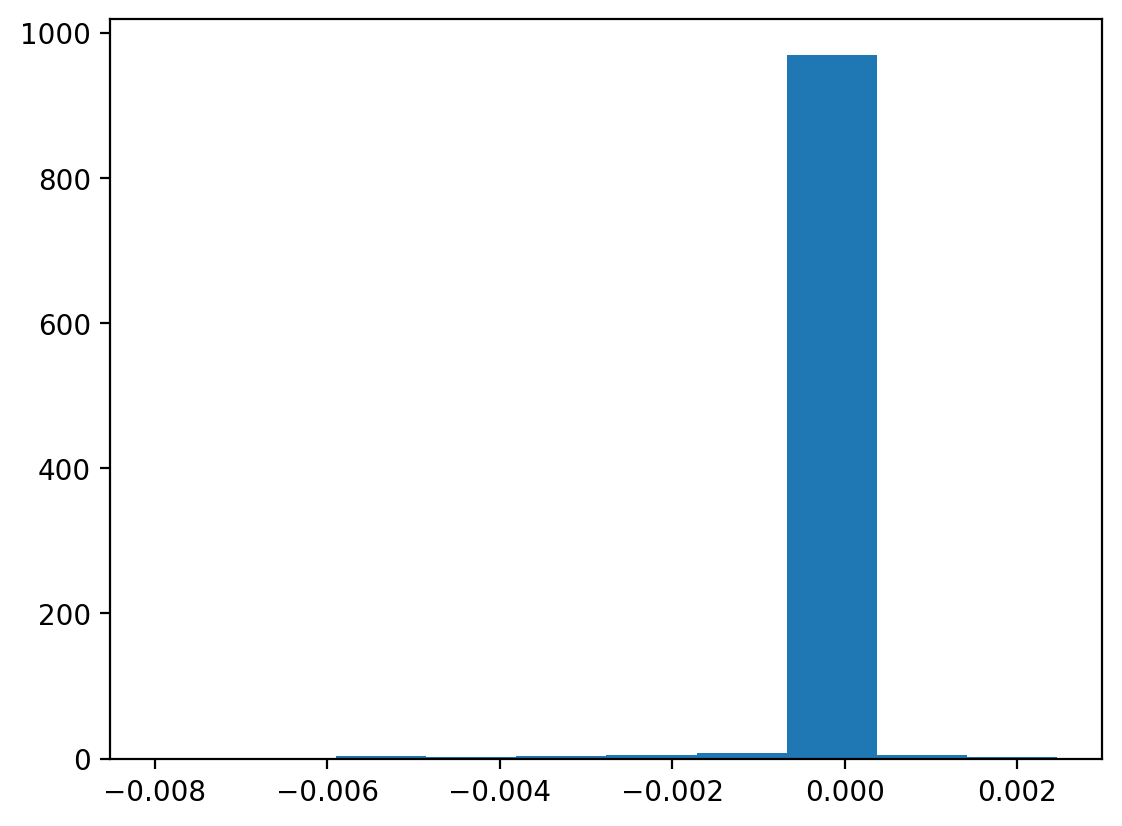

In [77]:
plt.hist(xcy[:, 2])

In [40]:
xcy = np.array(xcy)
xgy = np.array(xgy)
xggy = np.array(xggy)

In [41]:
x = xcy[:, 0]
y =xcy[:, 1] 
c1x = xgy[:, 0]
c1y = xgy[:, 1]
c2x = xgy[:, 2]
c2y = xgy[:, 3]
c3x = xgy[:, 4]
c3y = xgy[:, 5]
gc1x = xggy[:, 0]
gc1y = xggy[:, 1]
gc2x = xggy[:, 2]
gc2y = xggy[:, 3]
gc3x = xggy[:, 4]
gc3y = xggy[:, 5]

In [60]:
ix = np.where(x>0)
iy = np.where(y>0)

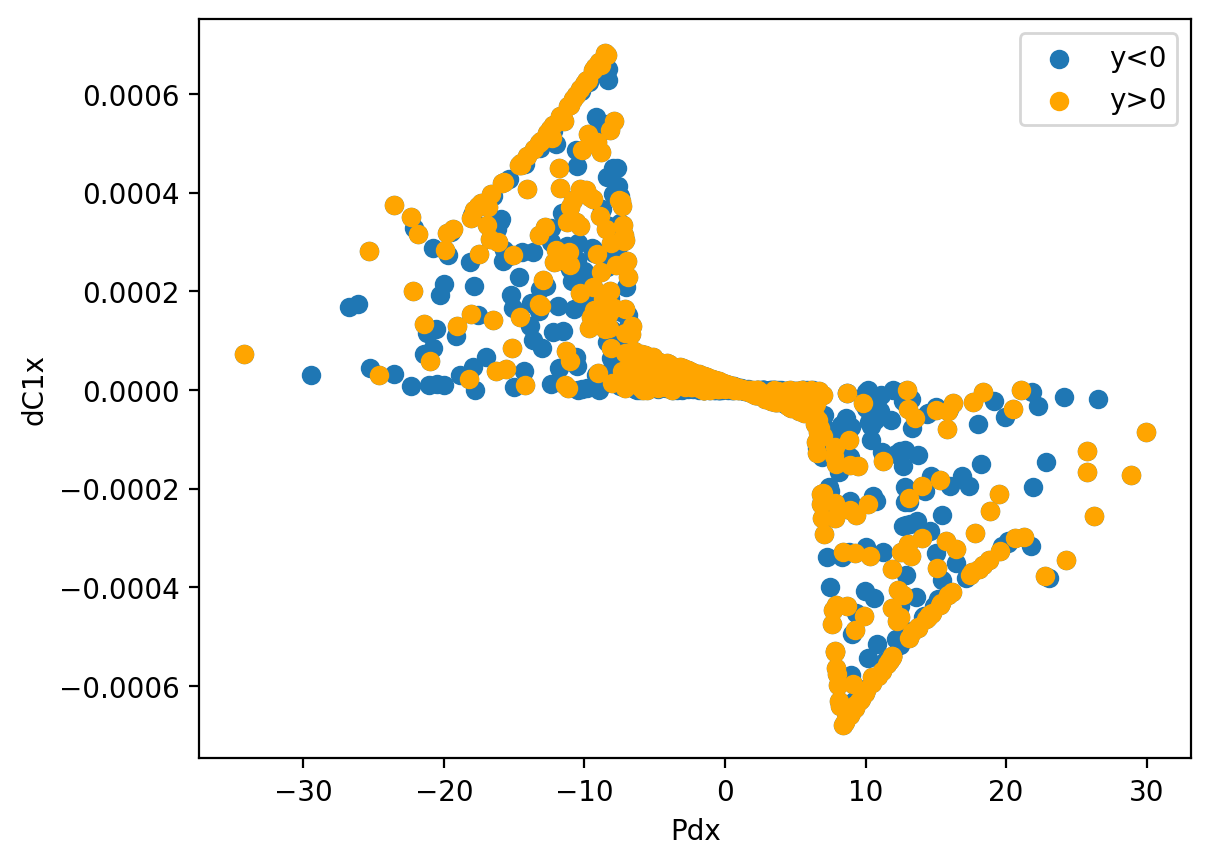

In [85]:
plt.scatter(x, c1x, label = "y<0")
plt.scatter(x[iy], c1x[iy], c='orange', label = "y>0")
plt.xlabel('Pdx')
plt.ylabel('dC1x')
plt.legend()

Text(0, 0.5, 'dC2x')

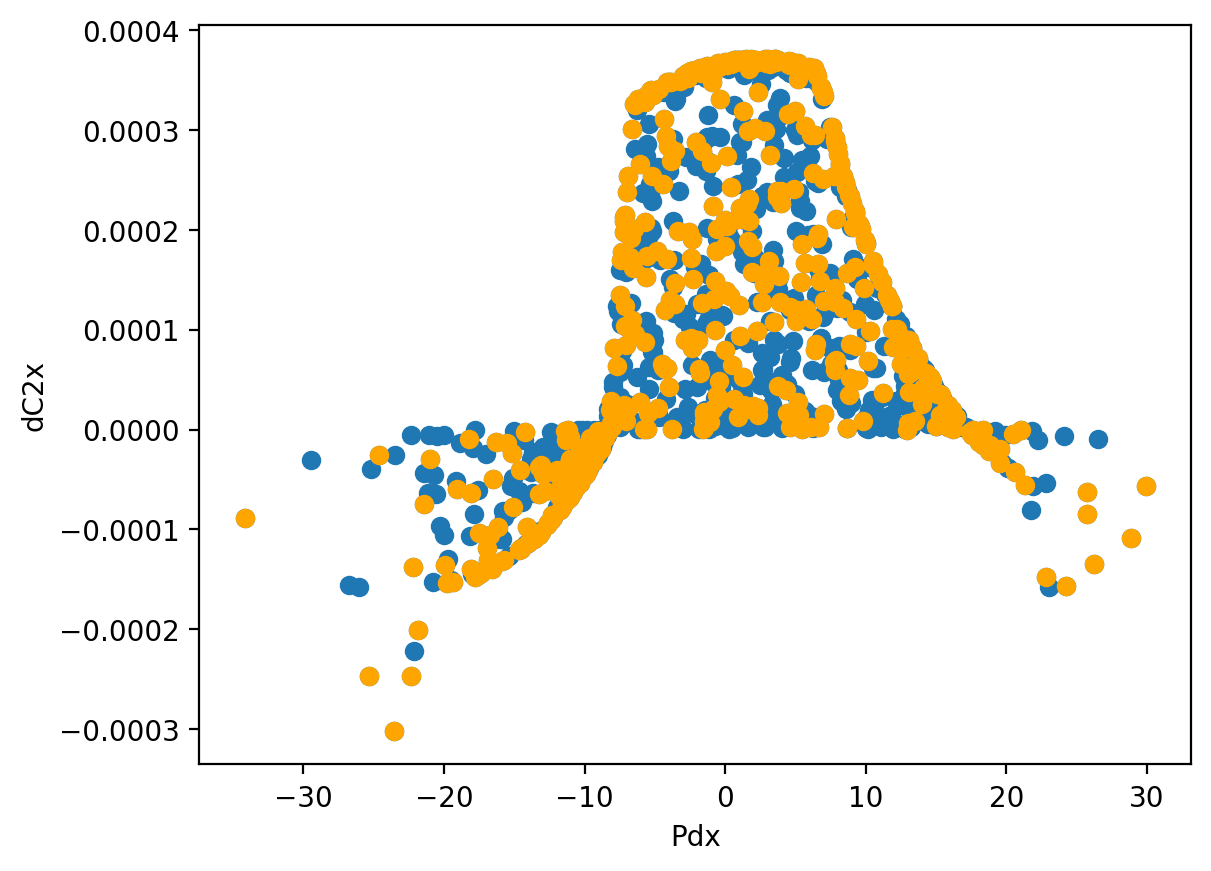

In [68]:
plt.scatter(x, c2x)
plt.scatter(x[iy], c2x[iy], c='orange')
plt.xlabel('Pdx')
plt.ylabel('dC2x')

Text(0, 0.5, 'dC3x')

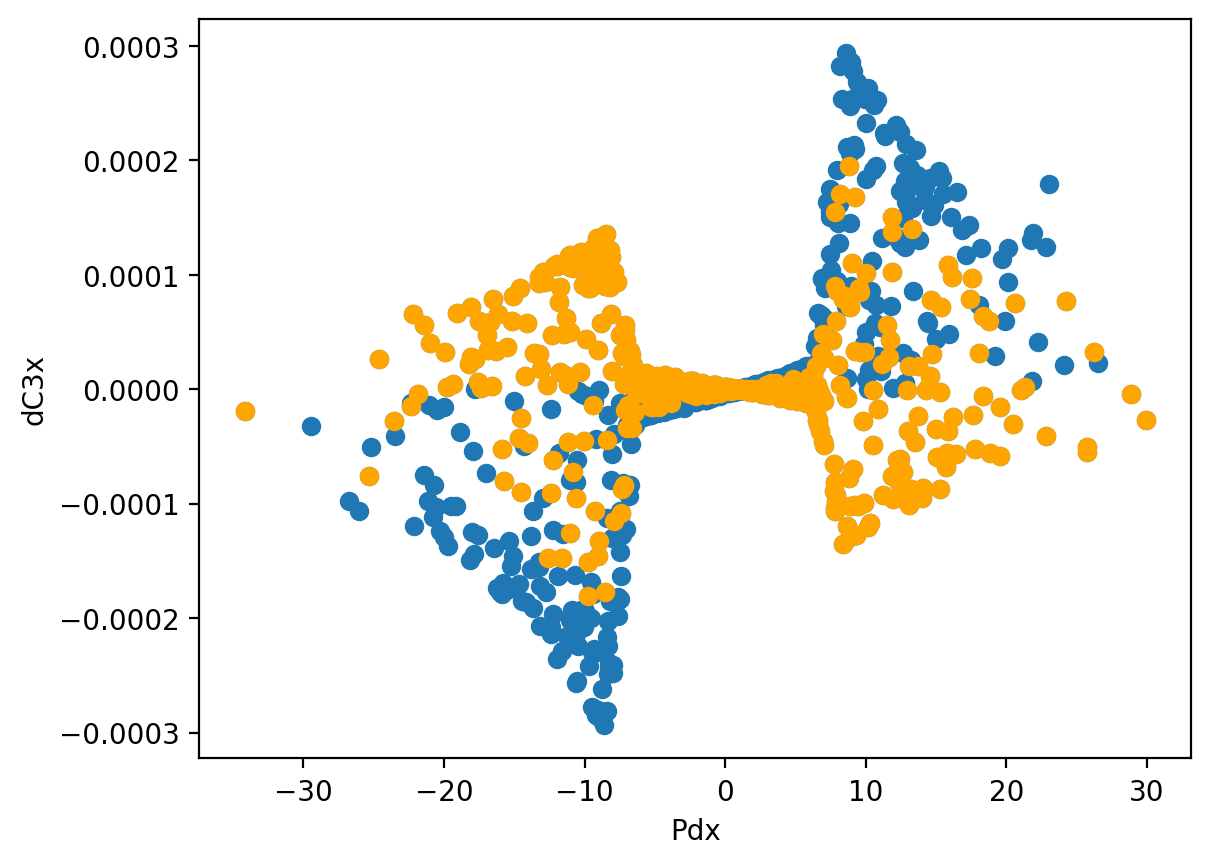

In [69]:
plt.scatter(x, c3x)
plt.scatter(x[iy], c3x[iy], c='orange')
plt.xlabel('Pdx')
plt.ylabel('dC3x')

Text(0, 0.5, 'dC1y')

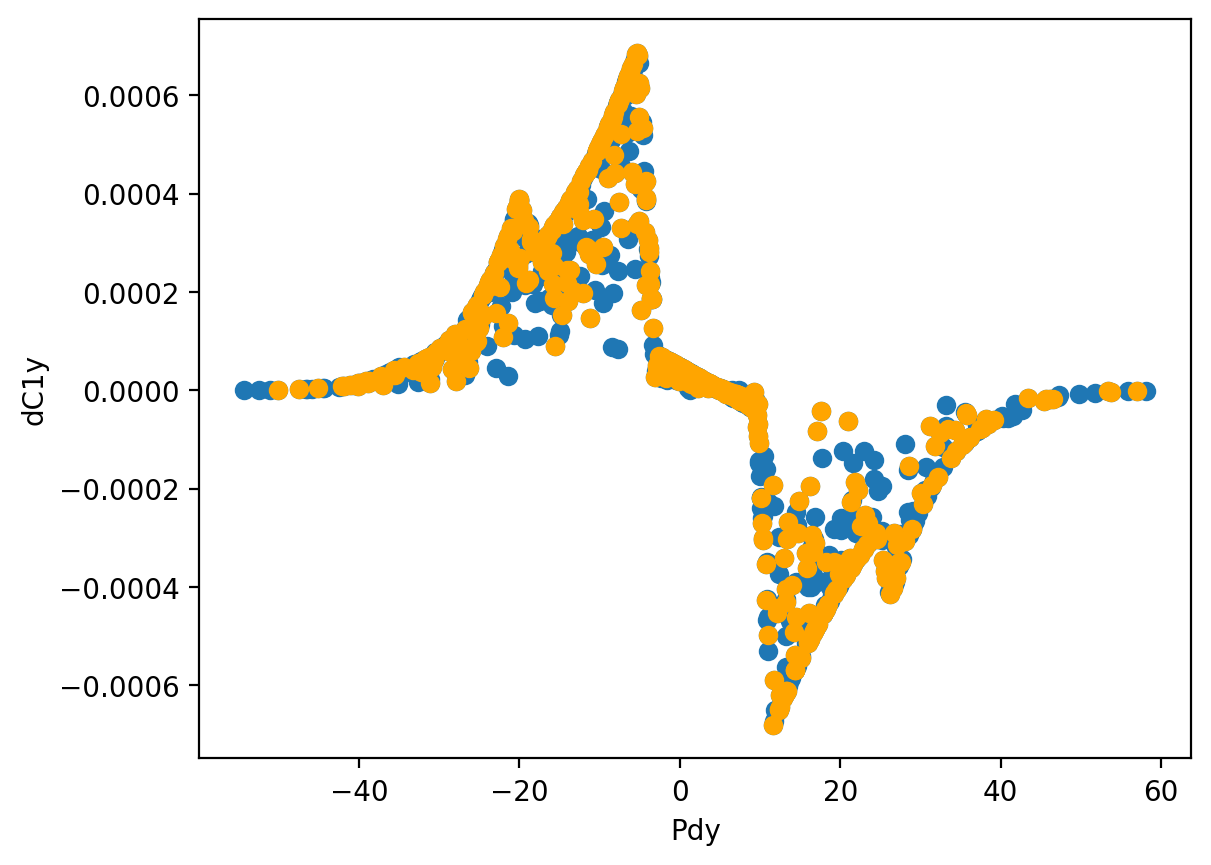

In [70]:
plt.scatter(y, c1y)
plt.scatter(y[ix], c1y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('dC1y')

Text(0, 0.5, 'dC2y')

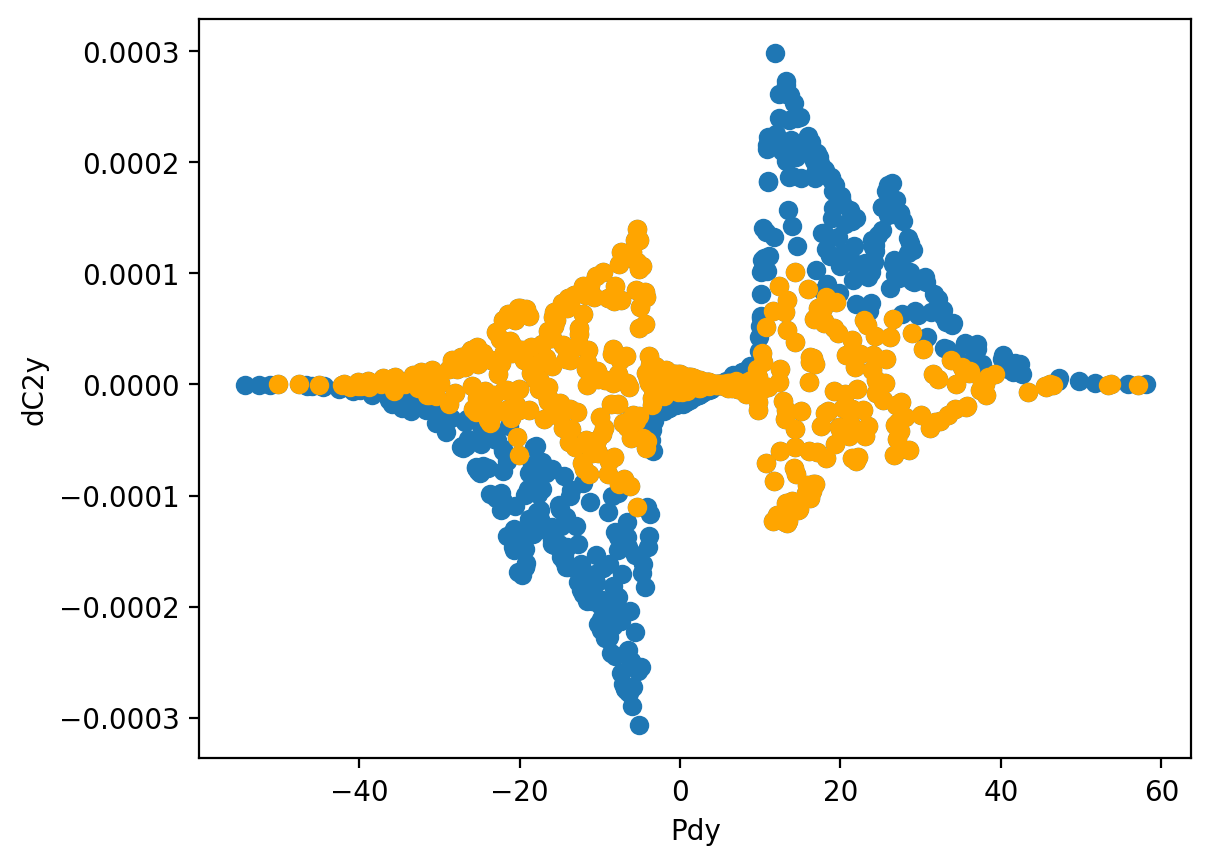

In [83]:
plt.scatter(y, c2y)
plt.scatter(y[ix], c2y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('dC2y')

Text(0, 0.5, 'dC3y')

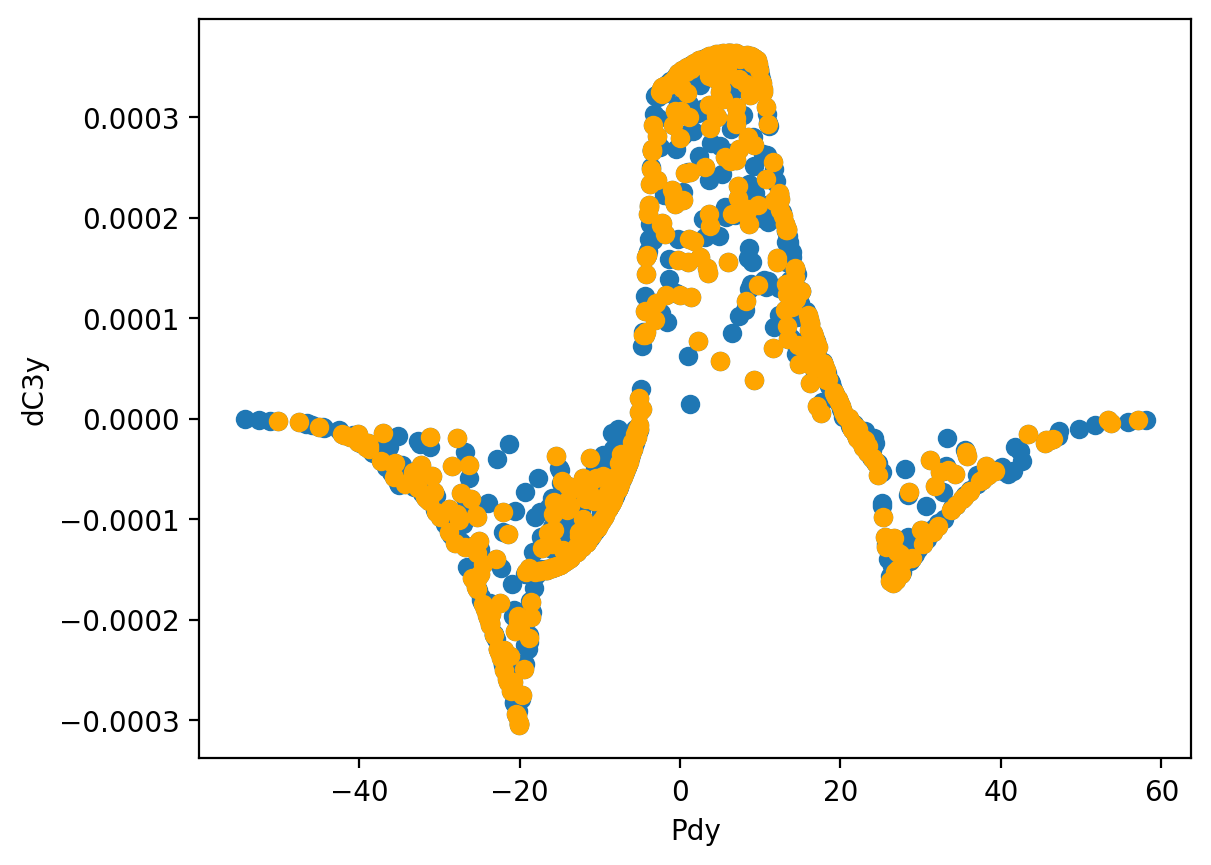

In [72]:
plt.scatter(y, c3y)
plt.scatter(y[ix], c3y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('dC3y')

Text(0, 0.5, 'd2C1x')

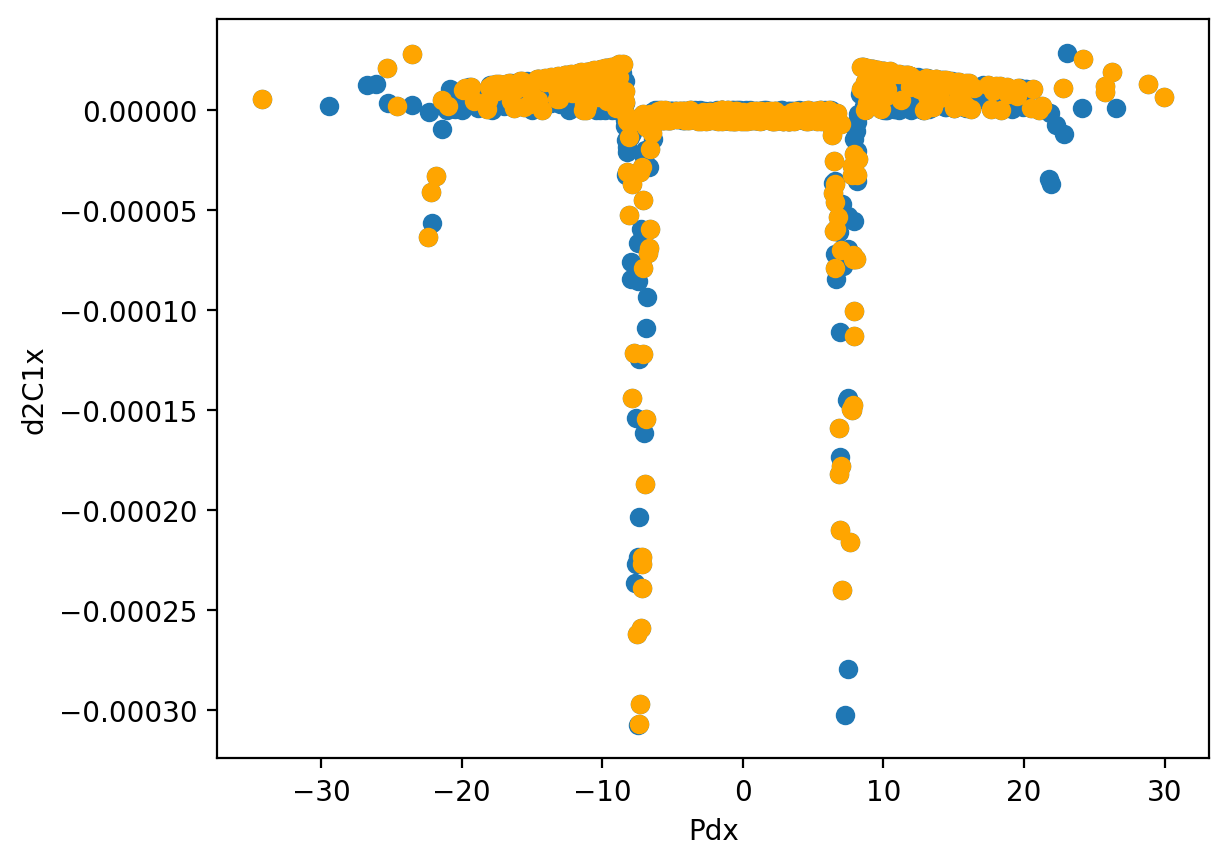

In [74]:
plt.scatter(x, gc1x)
plt.scatter(x[iy], gc1x[iy], c='orange')
plt.xlabel('Pdx')
plt.ylabel('d2C1x')

Text(0, 0.5, 'd2C2x')

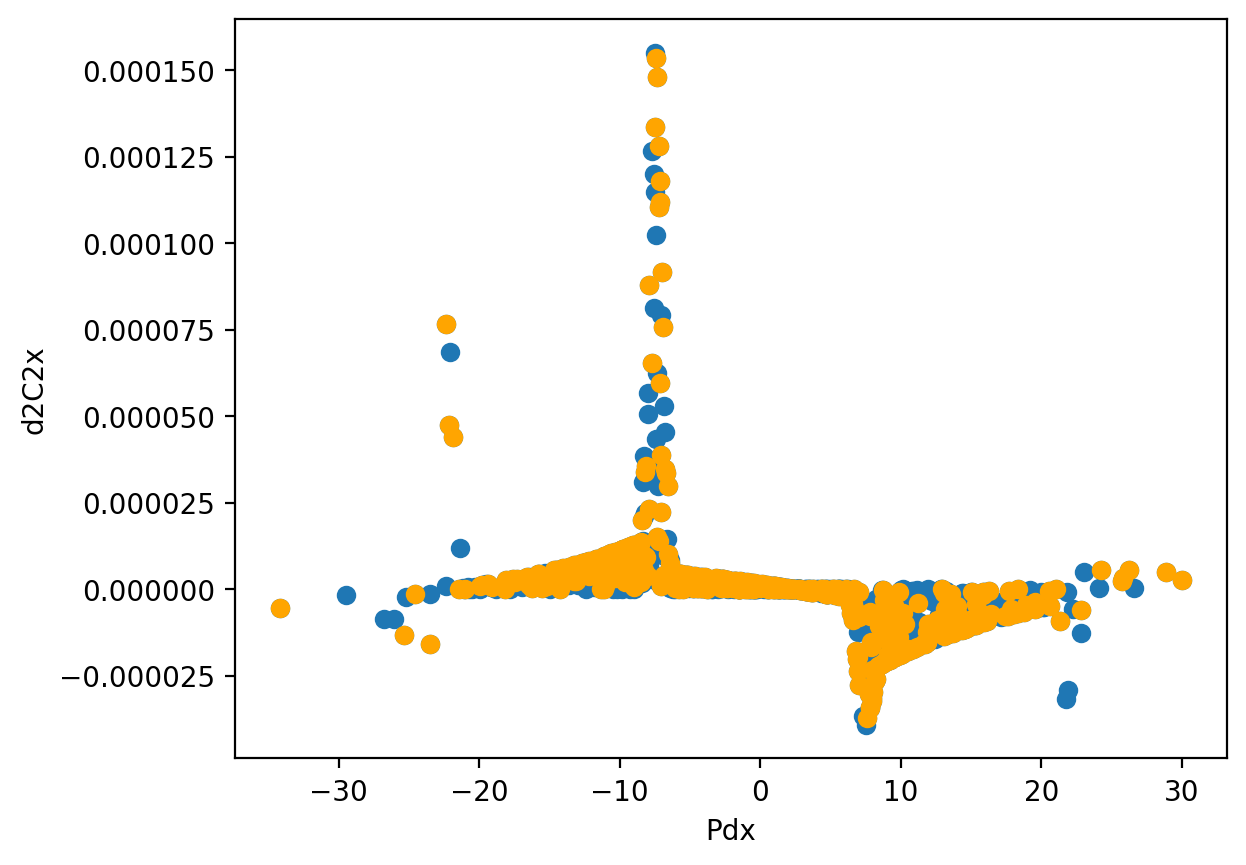

In [77]:
plt.scatter(x, gc2x)
plt.scatter(x[iy], gc2x[iy], c='orange')
plt.xlabel('Pdx')
plt.ylabel('d2C2x')

Text(0, 0.5, 'd2C3x')

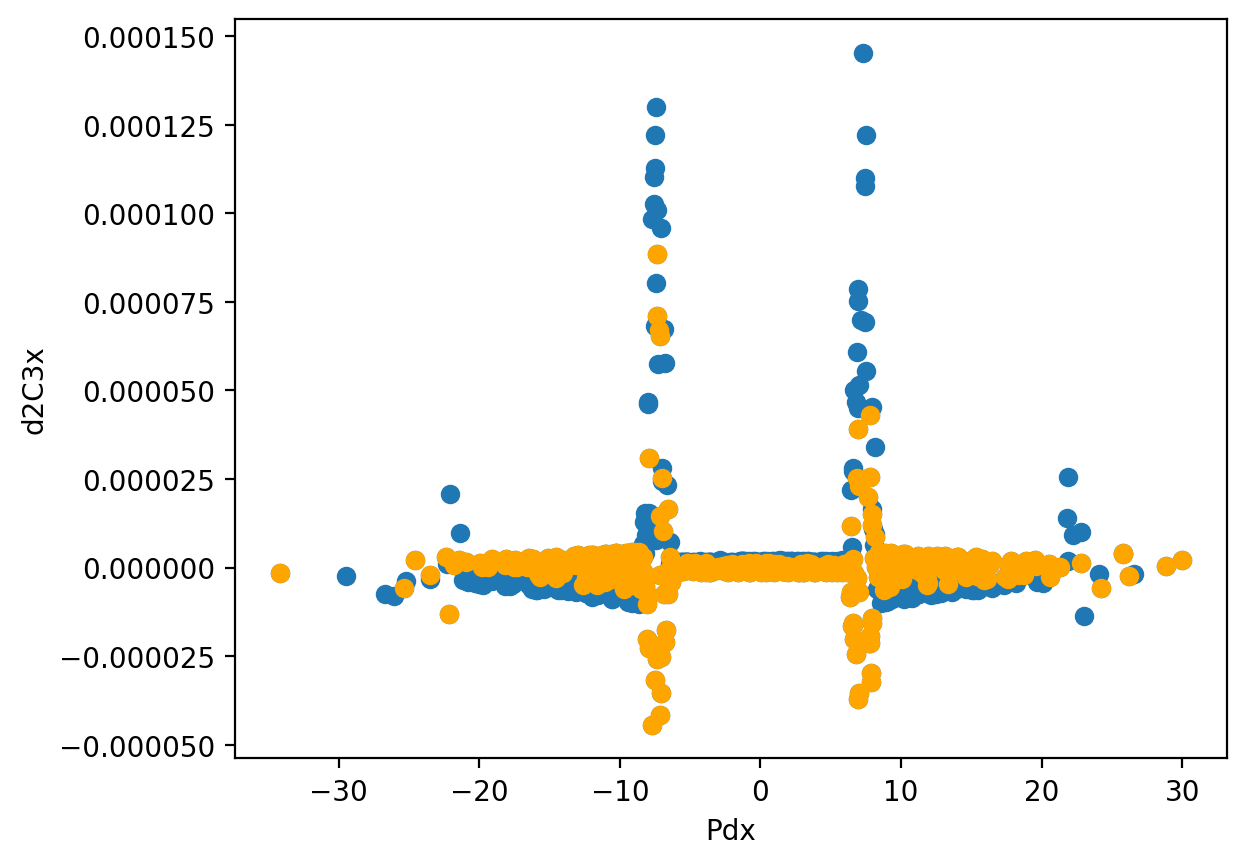

In [78]:
plt.scatter(x, gc3x)
plt.scatter(x[iy], gc3x[iy], c='orange')
plt.xlabel('Pdx')
plt.ylabel('d2C3x')

Text(0, 0.5, 'd2C1y')

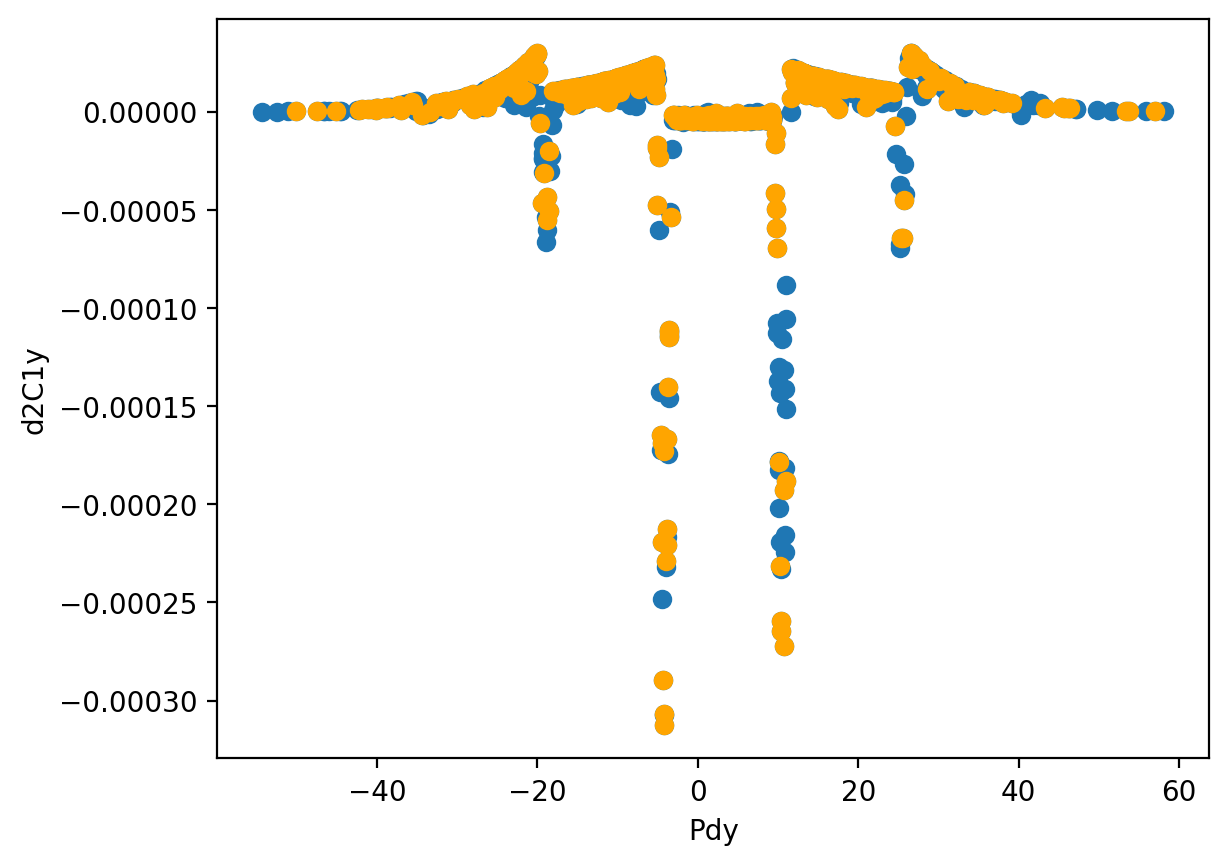

In [79]:
plt.scatter(y, gc1y)
plt.scatter(y[ix], gc1y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('d2C1y')

Text(0, 0.5, 'd2C2y')

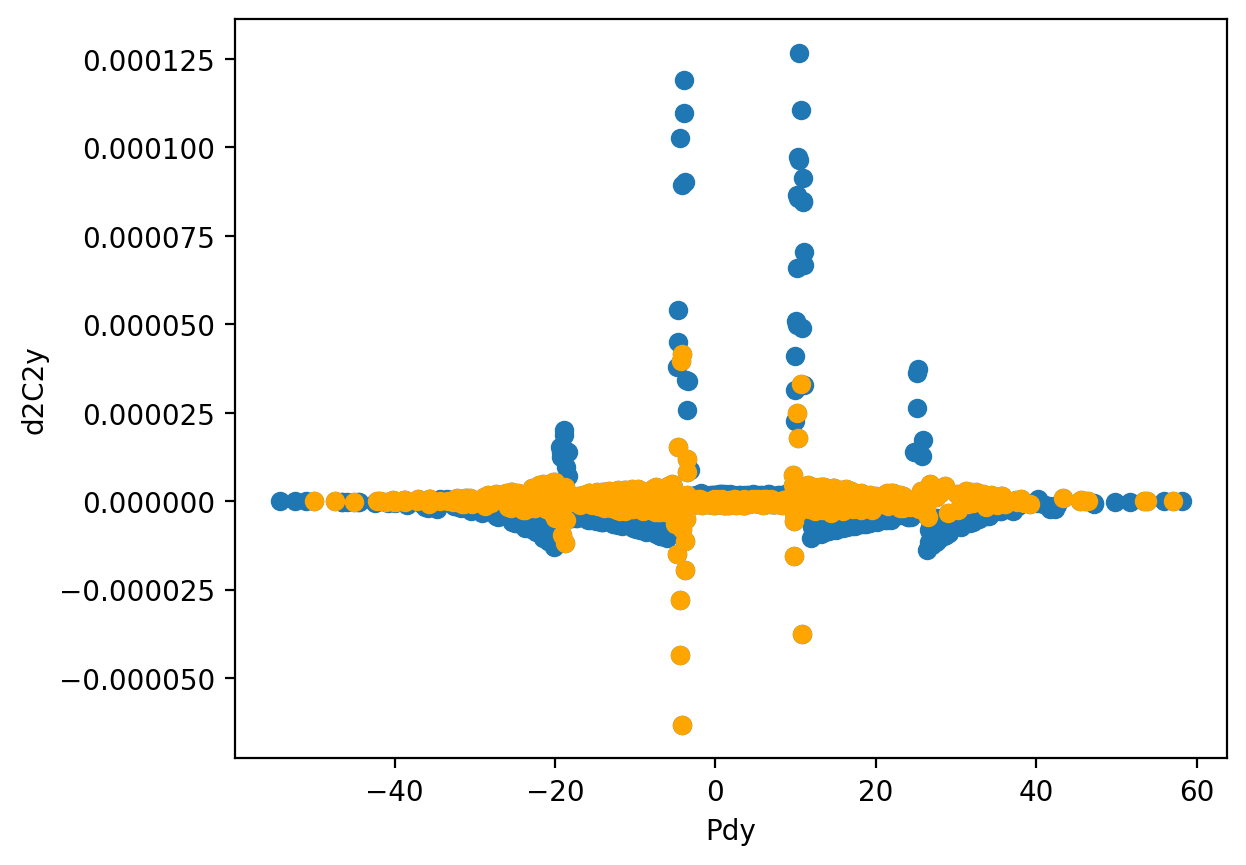

In [80]:
plt.scatter(y, gc2y)
plt.scatter(y[ix], gc2y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('d2C2y')

Text(0, 0.5, 'd2C3y')

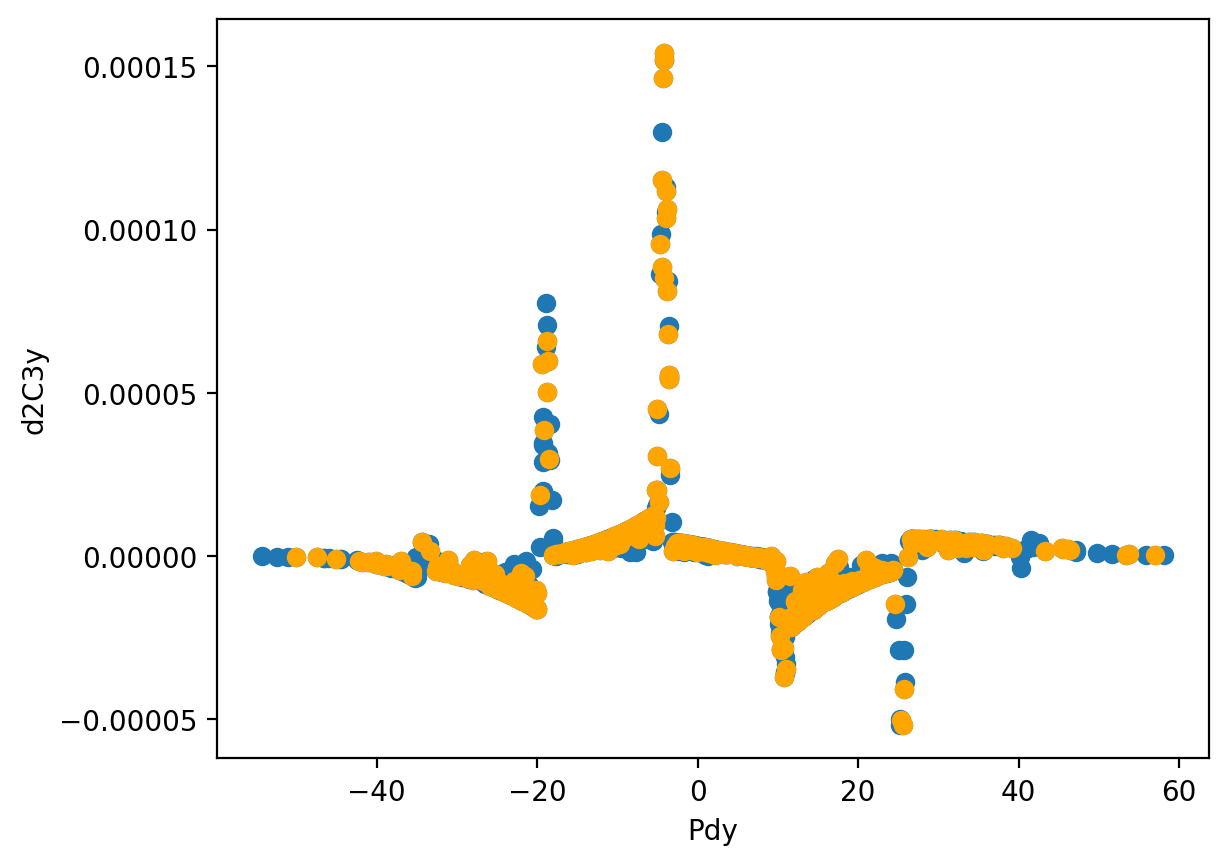

In [81]:
plt.scatter(y, gc3y)
plt.scatter(y[ix], gc3y[ix], c='orange')
plt.xlabel('Pdy')
plt.ylabel('d2C3y')

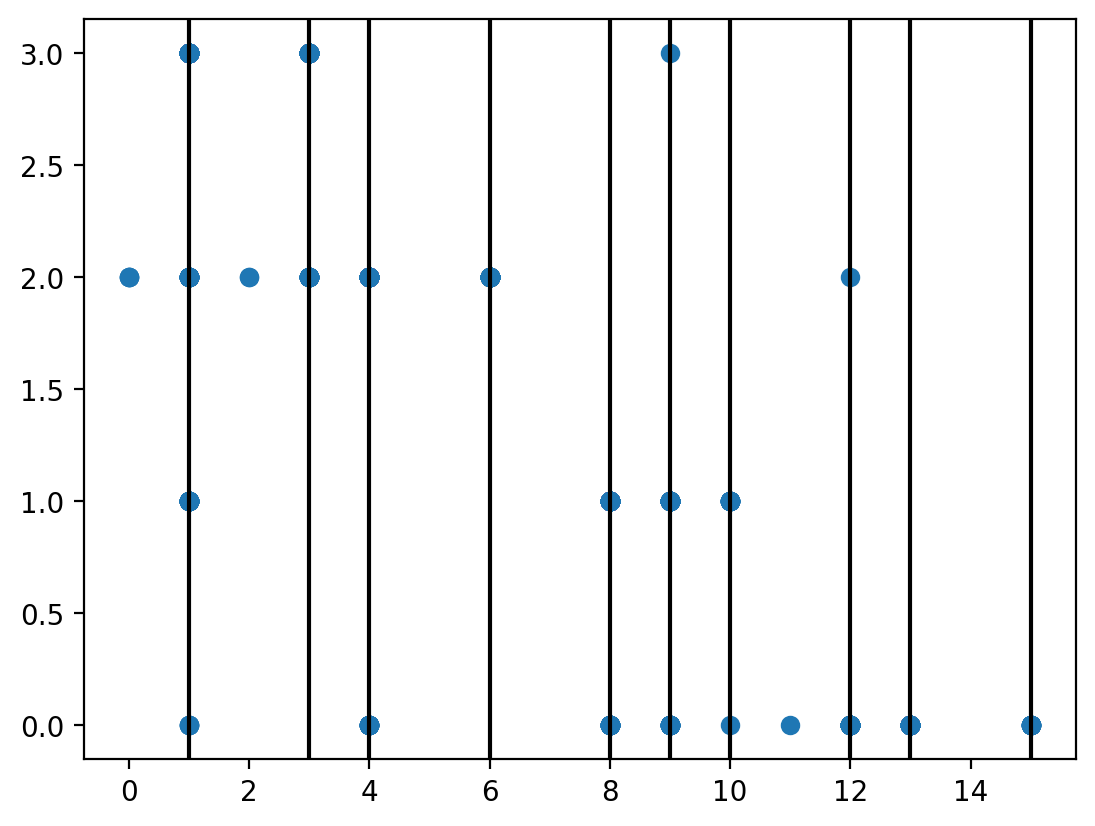

In [254]:
plt.axvline(x=1, c='k')
plt.axvline(x=3, c='k')
plt.axvline(x=4, c='k')
plt.axvline(x=6, c='k')
plt.axvline(x=8, c='k')
plt.axvline(x=9, c='k')
plt.axvline(x=10, c='k')
plt.axvline(x=12, c='k')
plt.axvline(x=13, c='k')
plt.axvline(x=15, c='k')
plt.scatter(xgy, xcy)

In [193]:
ix = np.where(agarsx>0)
#iy = np.where(agarsy>0)

In [194]:
[ax[i] for i in ix]

[array([ -8.041, -13.086,   1.778,   0.207,  -5.403, -10.601,  -2.788,
         -5.216,  -9.534,  -4.399,  -5.463,  -9.982, -20.909,  -0.407,
         -4.051,  -2.477, -12.033,  -7.473, -15.291, -12.9  ,   1.137,
        -15.778,  -5.368, -11.253,  -9.802,  -9.01 ,  -7.946, -10.579,
          1.199,  -6.296, -17.27 ,  -6.805,  -9.503, -14.816,  -8.757,
        -13.888,  -0.362, -10.416, -15.621, -16.615,  -0.39 ,  -4.436,
         -3.501,  -0.357,   0.832,  -6.251,   0.037,  -9.602,  -3.879,
         -0.592,  -1.541,   2.064,  -2.48 ,  -6.712,  -2.349,  -5.731])]

In [186]:
[ay[i] for i in iy]

[array([-2.2833e+01, -1.9869e+01, -1.3670e+01, -3.5742e+01, -1.3468e+01,
        -1.0938e+01, -2.5509e+01, -2.1100e-01, -3.2144e+01, -9.2800e-01,
        -3.1782e+01, -4.6225e+01, -7.3400e-01, -6.1400e-01, -1.4053e+01,
        -1.5479e+01, -2.1437e+01, -3.8400e-01, -2.2811e+01, -5.6850e+00,
        -4.0540e+00, -2.0208e+01, -4.1160e+00, -1.3382e+01, -1.9940e+00,
        -1.2980e+00, -2.3688e+01,  2.7310e+00,  5.7230e+00, -2.3314e+01,
        -2.6452e+01, -4.2000e-02,  2.7770e+00, -4.8324e+01, -8.7740e+00,
        -1.9920e+00, -4.0040e+00, -1.5787e+01, -1.2088e+01, -2.1208e+01,
        -3.4000e+00, -8.5600e-01, -2.1280e+00, -5.6310e+00, -8.1600e+00,
        -4.6137e+01, -1.6953e+01,  2.5780e+00, -2.0368e+01, -1.3432e+01,
         8.6000e-01, -1.8660e+00, -3.6952e+01, -4.8300e+00, -2.6580e+00,
        -2.0942e+01, -1.1204e+01, -2.7435e+01, -6.1460e+00, -8.7520e+00,
        -2.5500e+00])]

Text(0.5, 1.0, 'Histogram of Pdx with positive dC1')

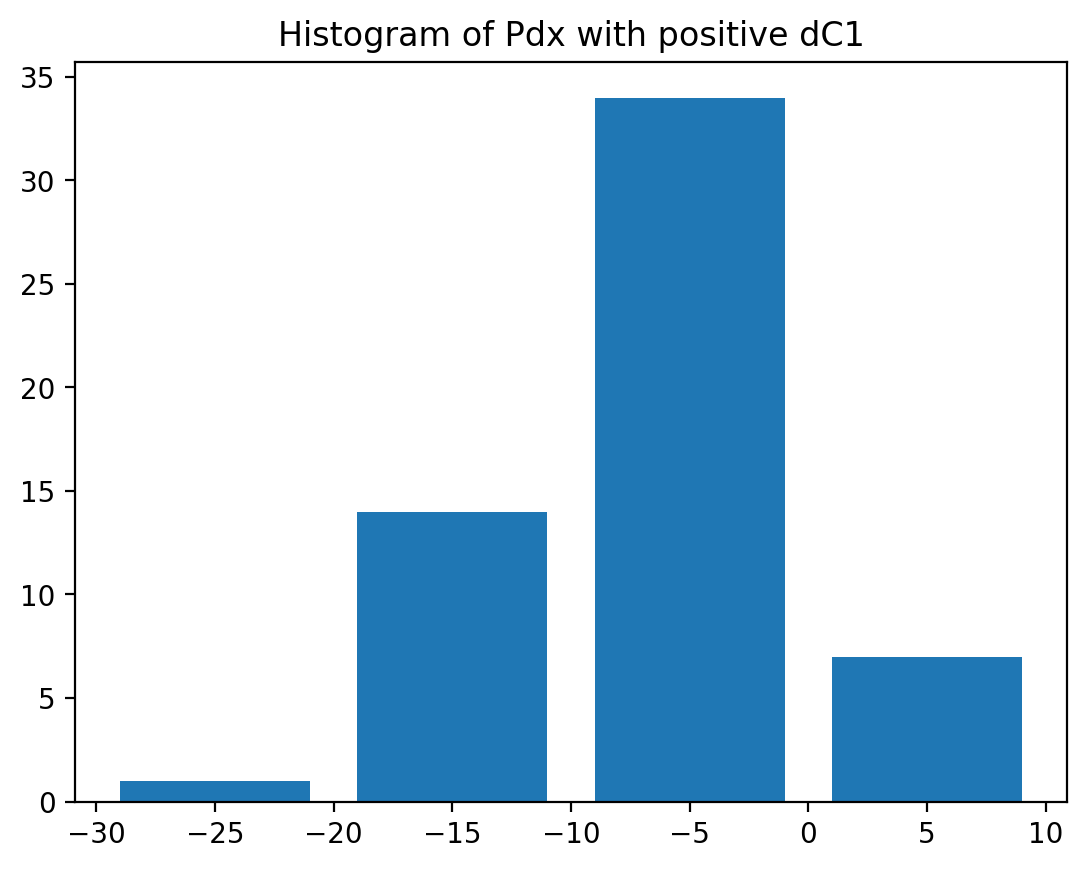

In [173]:
plt.hist([ax[i] for i in ix], bins = [-30, -20, -10, 0, 10], rwidth=0.8)
plt.title("Histogram of Pdx with positive dC1")

Text(0.5, 1.0, 'Histogram of Pdy with positive dC1')

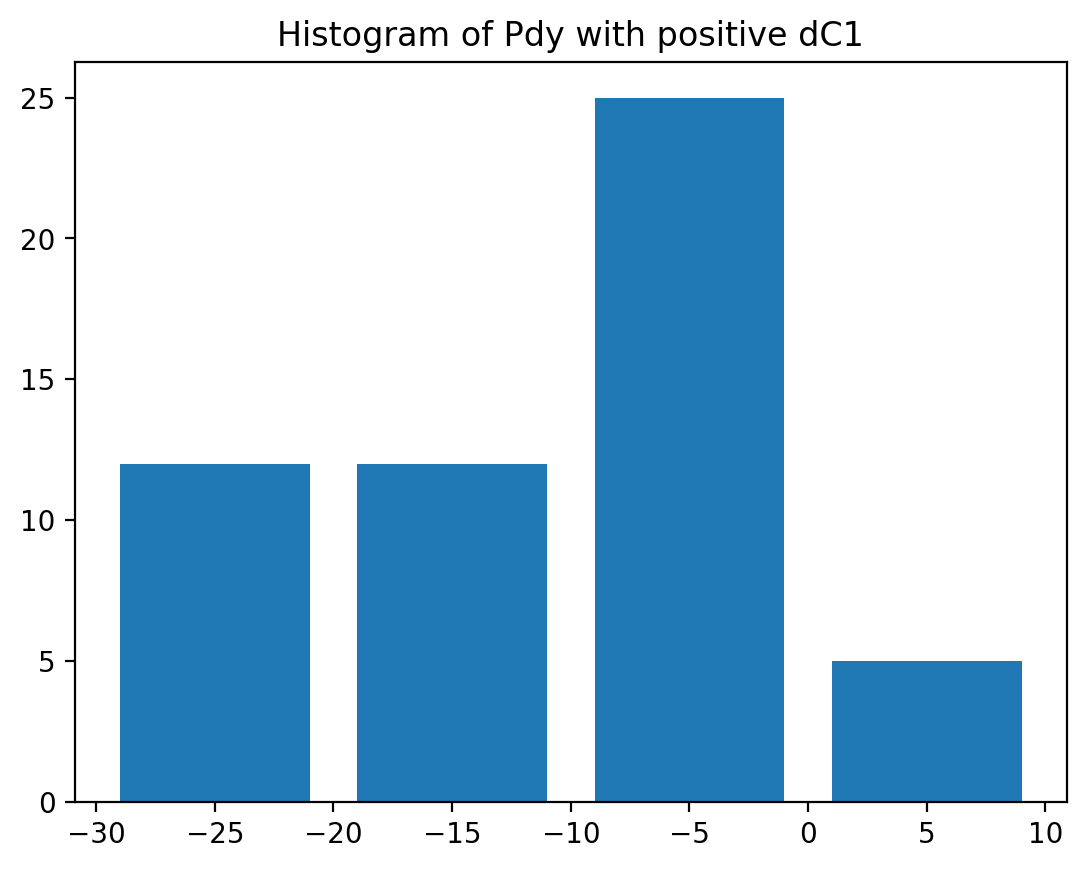

In [174]:
plt.hist([ay[i] for i in iy], bins = [-30, -20, -10, 0, 10], rwidth=0.8)
plt.title("Histogram of Pdy with positive dC1")